# Assignment 2: Module 1, Fuzzy Logic

---

## Practical 7: Mamdani Fuzzy Inference System

### Aim
To implement a simple Mamdani fuzzy inference system using scikit-fuzzy.

### Theory
In a Mamdani system, both the inputs and the output are fuzzy sets, and the rule conclusions are fuzzy sets too. The result is defuzzified to a crisp value. The example is a tipping system: the tip depends on the quality of service and food, both rated from 0 to 10.

Rules used:
- IF service is poor OR food is rancid THEN tip is low
- IF service is average THEN tip is medium
- IF service is good OR food is delicious THEN tip is high

### Implementation


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl

# 1. Inputs (antecedents) and output (consequent)
service = ctrl.Antecedent(np.arange(0, 11, 0.1), "service")
food = ctrl.Antecedent(np.arange(0, 11, 0.1), "food")
tip = ctrl.Consequent(np.arange(0, 26, 0.1), "tip")


In [2]:
# 2. Membership functions
service["poor"] = fuzz.trimf(service.universe, [0, 0, 5])
service["average"] = fuzz.trimf(service.universe, [0, 5, 10])
service["good"] = fuzz.trimf(service.universe, [5, 10, 10])

food["rancid"] = fuzz.trimf(food.universe, [0, 0, 5])
food["decent"] = fuzz.trimf(food.universe, [0, 5, 10])
food["delicious"] = fuzz.trimf(food.universe, [5, 10, 10])

tip["low"] = fuzz.trimf(tip.universe, [0, 0, 13])
tip["medium"] = fuzz.trimf(tip.universe, [0, 13, 25])
tip["high"] = fuzz.trimf(tip.universe, [13, 25, 25])


In [3]:
# 3. Rules
rule1 = ctrl.Rule(service["poor"] | food["rancid"], tip["low"])
rule2 = ctrl.Rule(service["average"], tip["medium"])
rule3 = ctrl.Rule(service["good"] | food["delicious"], tip["high"])

# 4. Build the system (Mamdani inference, centroid defuzzification)
tipping_ctrl = ctrl.ControlSystem([rule1, rule2, rule3])
tipping = ctrl.ControlSystemSimulation(tipping_ctrl)


In [4]:
# 5. Run the system for a sample input
tipping.input["service"] = 6.5
tipping.input["food"] = 9.8
tipping.compute()
print(f"Service = 6.5, Food = 9.8  ->  Tip = {tipping.output['tip']:.2f} %")

# 6. A few more inputs
print("\nService  Food   Tip (%)")
for s, f in [(1, 1), (5, 5), (9, 9), (3, 8)]:
    tipping.input["service"] = s
    tipping.input["food"] = f
    tipping.compute()
    print(f"{s:>5}  {f:>5}   {tipping.output['tip']:.2f}")


Service = 6.5, Food = 9.8  ->  Tip = 14.83 %

Service  Food   Tip (%)
    1      1   8.19
    5      5   12.67
    9      9   16.86
    3      8   13.36


### Visualization


e:\shivam projects\Assignement 1\.venv\Lib\site-packages\skfuzzy\control\fuzzyvariable.py:125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


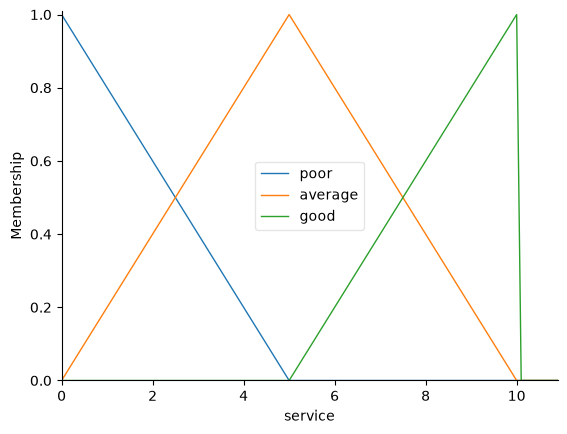

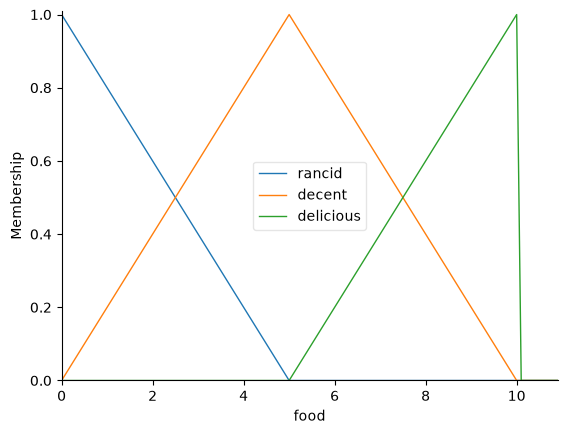

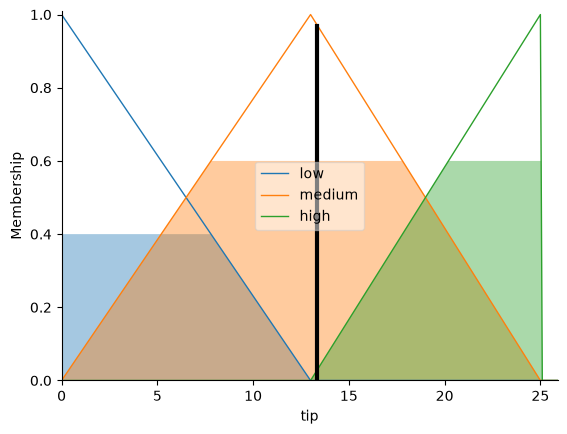

In [5]:
service.view()
food.view()
tip.view(sim=tipping)
plt.show()


### Observation
- For service 6.5 and food 9.8, the system gives a tip of 14.83 %. Service is mostly average and food is mostly delicious, so the medium and high rules both contribute.
- The tip rises as both inputs rise: 8.19 % at (1, 1), 12.67 % at (5, 5) and 16.86 % at (9, 9).
- The output is smooth, so small changes in the inputs give small changes in the tip.

### Conclusion
A Mamdani fuzzy inference system was built with scikit-fuzzy. It fuzzified two inputs, applied three rules, and gave a crisp tip percentage.
